<a href="https://colab.research.google.com/github/Ravikumar0604/Generative_modeling_casestudy/blob/main/Homework3_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial homework 3: XAI methods

In this homework, you will implement imputations to a dataset with missing values and measure the change of model predictions when compared with the original dataset

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


### Load california housing dataset

In [ ]:

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [ ]:
y.head()

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


### Predictions for dataset with 2 models

In [ ]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=RANDOM_STATE)

RF = RandomForestRegressor(random_state=RANDOM_STATE)

RF.fit(X_train,y_train)

predictions_RF = RF.predict(X_test)

mse_RF = mean_squared_error(y_test, predictions_RF)

print("RF MSE = ", mse_RF)

LinReg = LinearRegression()

LinReg.fit(X_train,y_train)

predictions_LR = LinReg.predict(X_test)

mse_LR = mean_squared_error(y_test, predictions_LR)

print("LR MSE = ", mse_LR)

RF MSE =  0.2603403202420427
LR MSE =  0.5369686543372456


We reduce the size of the test set to make computations faster

In [10]:
# This is the set you should use for your exercise
N_samples = 200
X_test_reduced = X_test.sample(N_samples, random_state=RANDOM_STATE)

In [11]:
# We calculate here the MSEs for the reduced sample
y_test_reduced = y_test.sample(N_samples, random_state=RANDOM_STATE)

predictions_RF_reduced = RF.predict(X_test_reduced)

mse_RF_reduced = mean_squared_error(y_test_reduced, predictions_RF_reduced)

print("RF MSE reduced = ", mse_RF_reduced)

predictions_LR_reduced = LinReg.predict(X_test_reduced)

mse_LR_reduced = mean_squared_error(y_test_reduced, predictions_LR_reduced)

print("LR MSE reduced = ", mse_LR_reduced)

RF MSE reduced =  0.36325763886261114
LR MSE reduced =  0.6096461132311998


## EXERCISE STARTS HERE

### Feature importance and model explanation with Shapley values

Use SHAP on the dataset to find the most important features for each of the trained models.

#### 1) Compute Shapley values for the Random Forest model trained above. Use the X_test_reduced set to compute the values. Either by making a summary_plot or by computing the average Shapley value per feature, find the most important features in the dataset in order.
You will be asked for either the 1st or 2nd or 3rd, etc most important feature according to this model.

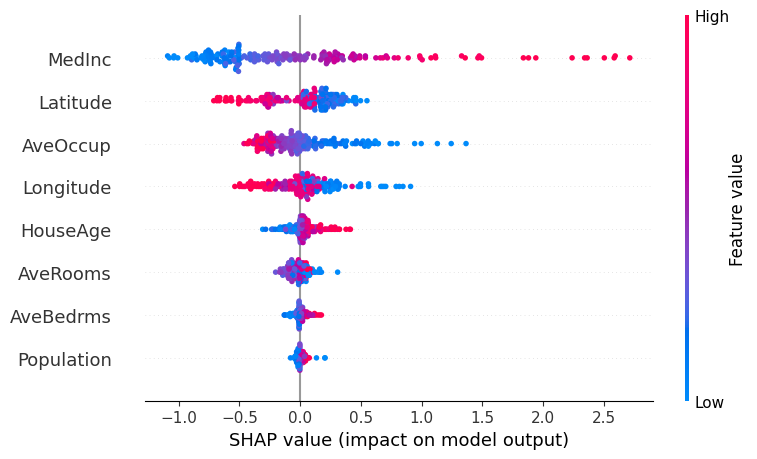

,feature,importance
0,MedInc,0.588124
6,Latitude,0.243634
5,AveOccup,0.240049
7,Longitude,0.197187
1,HouseAge,0.084949
2,AveRooms,0.059695
3,AveBedrms,0.030309
4,Population,0.021183


In [12]:
# 1) Install shap if not present, and compute Shapley values for the Random Forest model
!pip install shap -q
import shap

# Compute TreeExplainer and SHAP values
explainer_rf = shap.TreeExplainer(RF)
shap_values_rf = explainer_rf(X_test_reduced)

# Plot the summary plot to visualize feature importance
shap.summary_plot(shap_values_rf, X_test_reduced)

# Compute and display mean absolute SHAP values for each feature
rf_importance = np.abs(shap_values_rf.values).mean(axis=0)
importance_df = pd.DataFrame({
    'feature': X_test_reduced.columns,
    'importance': rf_importance
}).sort_values(by='importance', ascending=False)

display(importance_df)

#### 2) Either by making a waterfall plot or computing it directly, find the Shapley values from above (i.e. for the Random Forest) for instance 22 of the set X_train_reduced.
You will be asked for one of these values for this particular instance.

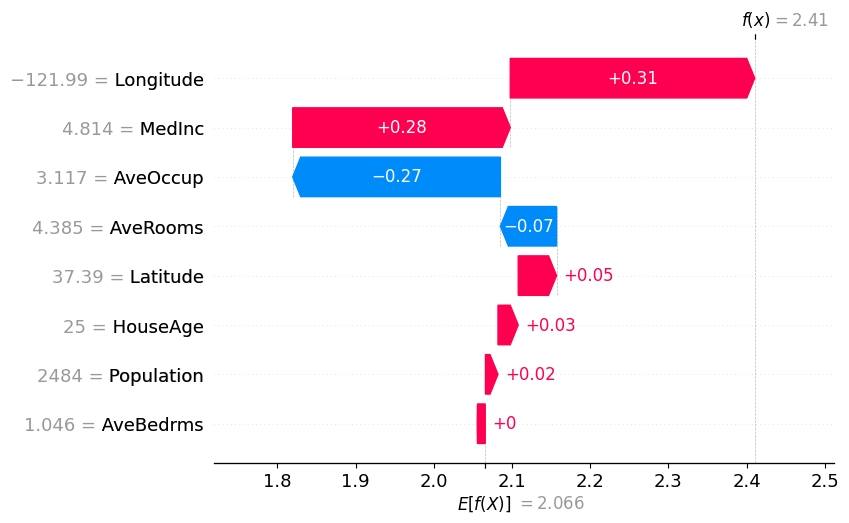

Base value (E[f(x)]): 2.0658288648683834
Instance SHAP values per feature:
MedInc: 0.278132
HouseAge: 0.025886
AveRooms: -0.071784
AveBedrms: 0.000337
Population: 0.015996
AveOccup: -0.265516
Latitude: 0.048983
Longitude: 0.312538


In [13]:
# 2) Find the Shapley values for instance 22 of X_test_reduced (note: the prompt says X_train_reduced, but the reference set is X_test_reduced. Let's provide a way to examine the instance and its SHAP values)
instance_index = 22

# Waterfall plot for instance at index 22
shap.plots.waterfall(shap_values_rf[instance_index])

# Print the SHAP values and base/output values explicitly
print("Base value (E[f(x)]):", shap_values_rf[instance_index].base_values)
print("Instance SHAP values per feature:")
for col, val in zip(X_test_reduced.columns, shap_values_rf[instance_index].values):
    print(f"{col}: {val:.6f}")

#### 3) Compute Shapley values for the Linear Regression model trained above (hint: use shap.LinearExplainer(model, X_train) instead of TreeExplainer). Again, use the X_test_reduced set to compute the values. Once you have the Shapley values, calculate the average Shapley value per feature for this model.
You will be asked for the average Shapley value for one of the features

In [14]:
# 3) Compute Shapley values for the Linear Regression model using LinearExplainer
explainer_lr = shap.LinearExplainer(LinReg, X_train)
shap_values_lr = explainer_lr(X_test_reduced)

# Calculate the average absolute Shapley value per feature
lr_importance = np.abs(shap_values_lr.values).mean(axis=0)
lr_importance_df = pd.DataFrame({
    'feature': X_test_reduced.columns,
    'mean_abs_shap': lr_importance
}).sort_values(by='mean_abs_shap', ascending=False)

display(lr_importance_df)

,feature,mean_abs_shap
6,Latitude,0.839000
7,Longitude,0.800022
0,MedInc,0.721352
2,AveRooms,0.173255
3,AveBedrms,0.151512
1,HouseAge,0.104128
5,AveOccup,0.002012
4,Population,0.000048
